# Text prompts: SAM 3 concept segmentation vs Grounded-SAM 2.1

"Pick up the mug" needs **open-vocabulary** segmentation: masks for objects named in free
text, including classes no detector was trained on. Until SAM 3 the standard recipe was a
two-stage **Grounded-SAM** pipeline - an open-vocabulary detector turns the text into
boxes, SAM turns the boxes into masks. SAM 3 instead does **Promptable Concept
Segmentation (PCS)** natively: one model takes a noun phrase (and/or example boxes) and
returns a mask, box and score for *every* matching instance.

**What you will learn**

1. The difference between *visual* prompts (PVS: "segment this object") and *concept*
   prompts (PCS: "segment all objects of this kind").
2. How SAM 3 decouples recognition from localisation with a **presence head**, and why
   that matters for prompts naming absent objects.
3. How to build Grounded-SAM from Grounding DINO + SAM 2.1 in `transformers`.
4. How to evaluate text-prompted instance segmentation with COCO-style **mask AP**, and
   how to measure hallucinations on absent concepts.

**Data**: a desk frame from TUM RGB-D `fr1_desk` (a typical robot workspace, no masks) for
the qualitative part, and coco8-seg / coco128-seg (COCO images with instance masks) for
the quantitative part. The `## Results` section loads the coco128-seg benchmark written by
`projects/05_segmentation/scripts/benchmark_coco.py --task text`. Hardware: RTX 5060
Laptop GPU (8 GB). Prerequisite: `make data-05_segmentation`.

## Setup

Imports, seeding, device and plotting style.

In [1]:
# --- Setup: imports, device, paths, plotting style ---
# segkit (projects/05_segmentation/scripts/segkit.py) holds the data loaders, metrics and
# model adapters shared by all notebooks of this project, the benchmark script and the solutions.
# Photo grids are displayed with sk.show_jpeg (JPEG is ~5-10x smaller than PNG for photos);
# charts stay PNG via plt.show().
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from cvlab import device as cvdevice
from cvlab import viz
from cvlab.bench import benchmark
from cvlab.device import track_vram
from cvlab.io import project_dir, repo_root

PROJECT = "05_segmentation"
sys.path.insert(0, str(project_dir(PROJECT) / "scripts"))
import segkit as sk  # noqa: E402

device = cvdevice.setup(seed=0)
viz.set_style()
warnings.filterwarnings("ignore")  # silence library warnings in the rendered notebook
from transformers.utils import logging as hf_logging  # noqa: E402

hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()
RESULTS = sk.results_dir()
print("results dir:", RESULTS.relative_to(repo_root()))

python 3.12.16 | torch 2.11.0+cu128 (CUDA 12.8) | torchvision 0.26.0+cu128 | numpy 2.5.4 | opencv 5.0.0
device: cuda | GPU: NVIDIA GeForce RTX 5060 Laptop GPU (7.53 GB, sm_120)


results dir: projects/05_segmentation/results


## A robot workspace

Frame 300 of TUM RGB-D `freiburg1_desk` (640x480, Kinect v1): monitors, a laptop, books,
cables and small clutter - the kind of scene a tabletop manipulator must parse into
objects. We will ask both pipelines for a few everyday concepts.

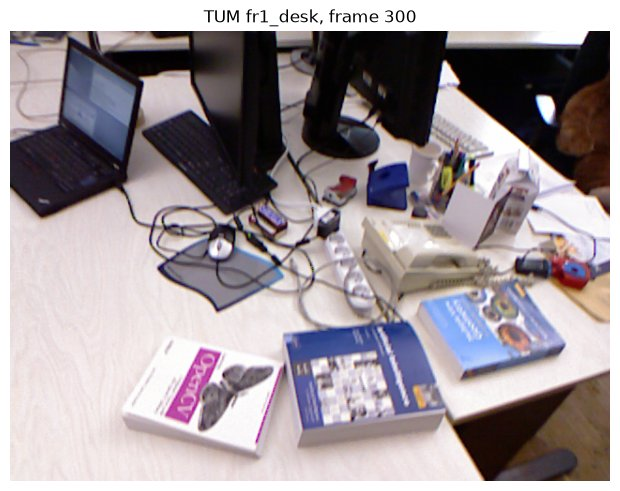

In [2]:
# --- Load a TUM RGB-D desk frame (shared dataset, see scripts/download_shared.py) ---
from cvlab.io import data_dir
from cvlab.tum import load_sequence

desk_seq = load_sequence(data_dir("tum", "fr1_desk", "rgbd_dataset_freiburg1_desk"))
desk = desk_seq.rgb(300)  # 480 x 640 x 3 uint8 RGB
QUERIES = ["computer monitor", "laptop", "keyboard", "book", "cable", "mug"]
fig, ax = plt.subplots(figsize=(6.4, 4.8))
ax.imshow(desk)
ax.set_title("TUM fr1_desk, frame 300")
ax.axis("off")
sk.show_jpeg(fig)  # photos: JPEG keeps the notebook small

## SAM 3: concept prompts

SAM 3 encodes the image with its **Perception Encoder** (a ViT shared with the text
encoder) and runs a DETR-style detector: a fixed set of object queries cross-attend to
the image features *conditioned on the prompt tokens*, and each query predicts a box, a
mask and a match score. The key addition is a global **presence token** that answers "is
this concept in the image at all?". The final score of query $i$ factorises as

$$s_i = \underbrace{p(\text{concept present} \mid \text{image})}_{\text{presence head}}
        \cdot \underbrace{p(\text{query } i \text{ matches} \mid \text{present})}_{\text{localisation}},$$

so a query no longer has to decide alone, from its local evidence, whether the concept
exists anywhere in the image. As with SAM 1/2 the vision features are computed once per
image; each new phrase only re-runs the text encoder and the detector heads.

In [3]:
# --- SAM 3 (Sam3Model) text prompts on the desk frame ---
# set_image runs the vision backbone once; each phrase reuses the cached features.
torch.cuda.empty_cache()
with track_vram() as mem_sam3:
    concept = sk.ConceptSegmenter(device=str(device))
    concept.set_image(desk)
    sam3_desk = {q: concept.segment(q, threshold=0.5) for q in QUERIES}
for q, r in sam3_desk.items():
    print(f"{q:18s}: {len(r['scores'])} instance(s), scores {np.round(r['scores'], 2)}")
print(f"SAM 3 ({concept.n_params_m:.0f} M params): peak VRAM {mem_sam3.peak_mb:.0f} MiB")

computer monitor  : 2 instance(s), scores [0.81 0.93]
laptop            : 1 instance(s), scores [0.98]
keyboard          : 3 instance(s), scores [0.71 0.88 0.89]
book              : 3 instance(s), scores [0.97 0.98 0.98]
cable             : 2 instance(s), scores [0.59 0.55]
mug               : 1 instance(s), scores [0.69]
SAM 3 (840 M params): peak VRAM 1981 MiB


## Grounded-SAM 2.1: detector boxes as SAM prompts

**Grounding DINO** fuses BERT text features and Swin image features in a cross-modality
decoder; each of its 900 queries predicts a box and a similarity to every text token. A
box is kept if its best token similarity exceeds `box_threshold` (0.35 here) and the
tokens above `text_threshold` (0.25) form its label - the defaults of the Grounded-SAM
reference code. The boxes are then fed to SAM 2.1-S as box prompts. Grounding DINO has no
presence head: the box scores are the only evidence that the object exists.

In [4]:
# --- Grounded-SAM 2.1: Grounding DINO tiny boxes -> SAM 2.1-S masks ---
# Both models stay on the GPU together (Grounding DINO fp32, SAM 2.1 bf16). SAM 3 is still
# loaded (we reuse it below), so we report the peak *above* the memory already allocated.
torch.cuda.empty_cache()
base_mib = torch.cuda.memory_allocated() / 2**20  # SAM 3 weights + cached features
with track_vram() as mem_gs:
    grounded = sk.GroundedSam(sk.SAM2_IDS["small"], device=str(device))
    grounded.set_image(desk)
    gsam_desk = {q: grounded.segment(q) for q in QUERIES}
for q, r in gsam_desk.items():
    print(f"{q:18s}: {len(r['scores'])} instance(s), scores {np.round(r['scores'], 2)}")
n_params = grounded.detector.n_params_m + grounded.sam.n_params_m
print(f"Grounding DINO-T + SAM 2.1-S ({n_params:.0f} M params): peak VRAM "
      f"{mem_gs.peak_mb - base_mib:.0f} MiB (on top of the {base_mib:.0f} MiB held by SAM 3)")

computer monitor  : 0 instance(s), scores []
laptop            : 2 instance(s), scores [0.63 0.43]
keyboard          : 1 instance(s), scores [0.39]
book              : 3 instance(s), scores [0.64 0.63 0.59]
cable             : 0 instance(s), scores []
mug               : 1 instance(s), scores [0.64]
Grounding DINO-T + SAM 2.1-S (211 M params): peak VRAM 1869 MiB (on top of the 1753 MiB held by SAM 3)


Side by side, one panel per phrase (SAM 3 on top, Grounded-SAM 2.1 below; colours =
instances of that phrase, the number in the title = instances found):

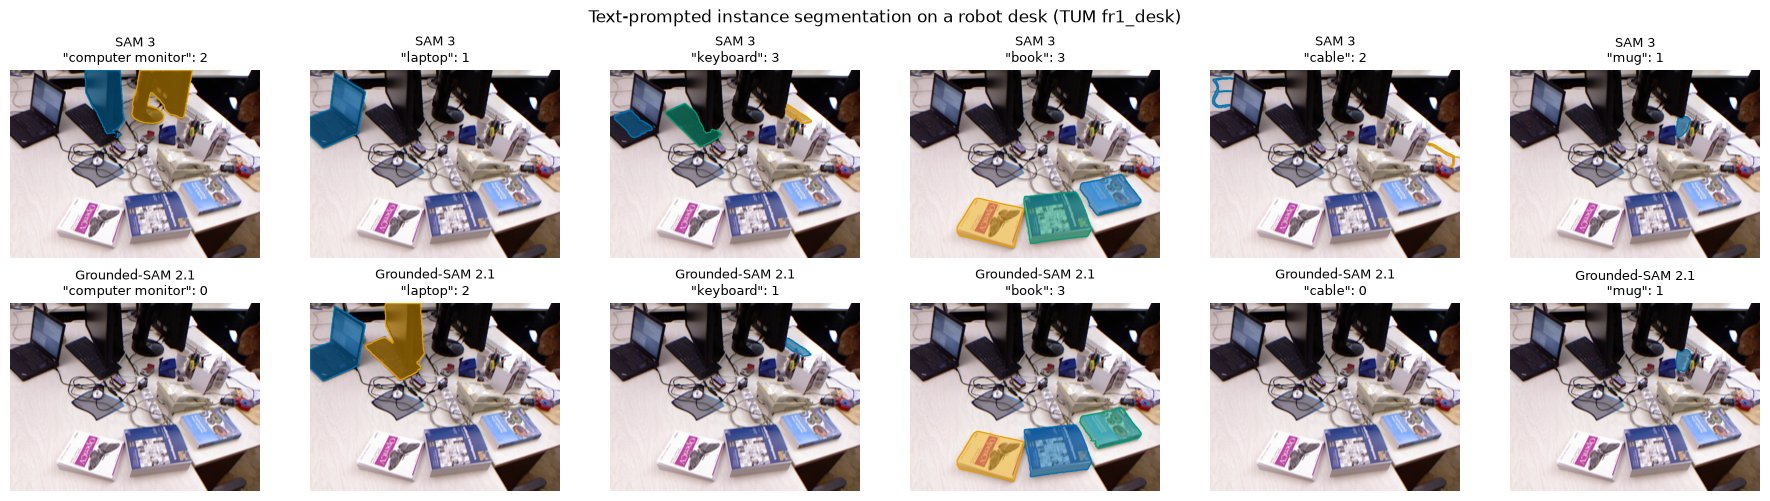

In [5]:
# --- Figure: SAM 3 vs Grounded-SAM 2.1 for each phrase on the desk frame ---
fig, axes = plt.subplots(2, len(QUERIES), figsize=(3.0 * len(QUERIES), 4.9))
for col, q in enumerate(QUERIES):
    for row, (name, res) in enumerate([("SAM 3", sam3_desk), ("Grounded-SAM 2.1", gsam_desk)]):
        r = res[q]
        img = viz.overlay_masks(desk, r["masks"]) if len(r["scores"]) else desk
        axes[row, col].imshow(img)
        axes[row, col].set_title(f'{name}\n"{q}": {len(r["scores"])}', fontsize=9)
        axes[row, col].axis("off")
fig.suptitle("Text-prompted instance segmentation on a robot desk (TUM fr1_desk)")
viz.savefig(fig, PROJECT, "desk_text_prompts")
sk.show_jpeg(fig)

## Visual exemplars and negative prompts

Text is not the only concept prompt: a **box exemplar** says "more objects like this one".
SAM 3 encodes the exemplar box (position + pooled image features) as extra prompt tokens.
A *negative* exemplar (label 0) removes a sub-concept. Here we draw one positive box on
the first "book" SAM 3 found and ask for all similar objects, without any text.

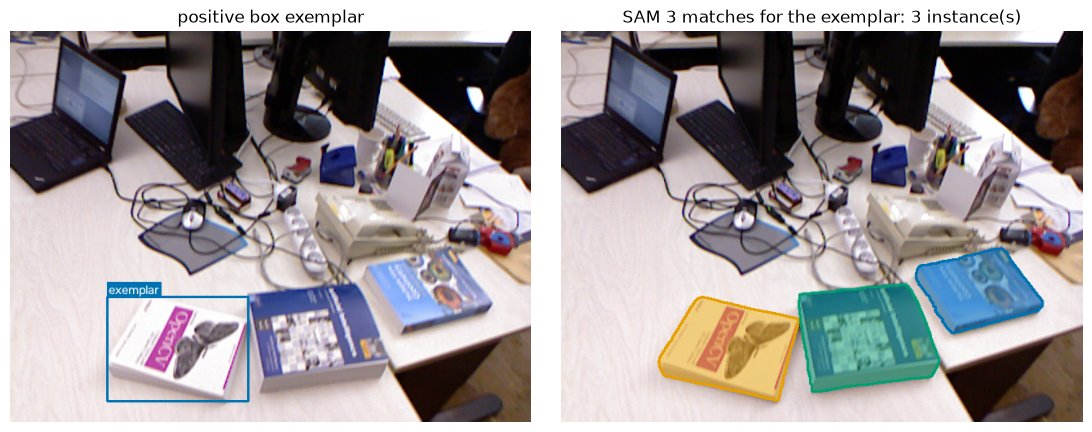

scores: [0.96 0.99 0.97]


In [6]:
# --- SAM 3 with a box exemplar instead of text ---
# Exemplar = the highest-scoring "book" box from above (x1, y1, x2, y2 pixels).
ex_box = sam3_desk["book"]["boxes"][int(np.argmax(sam3_desk["book"]["scores"]))].tolist()
ex = concept.segment(None, boxes=[ex_box], box_labels=[1], threshold=0.5)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].imshow(viz.draw_boxes(desk, np.array([ex_box]), labels=["exemplar"]))
axes[0].set_title("positive box exemplar")
axes[1].imshow(viz.overlay_masks(desk, ex["masks"]) if len(ex["scores"]) else desk)
axes[1].set_title(f"SAM 3 matches for the exemplar: {len(ex['scores'])} instance(s)")
for ax in axes:
    ax.axis("off")
sk.show_jpeg(fig)
print("scores:", np.round(ex["scores"], 2))

## Prompts for objects that are not there

A robot asked for "the banana" on a desk without bananas should answer "none". This is
where the two designs differ: Grounding DINO scores every box against the phrase, so with
a single phrase it can put a confident box on the most similar-looking thing, while
SAM 3's presence head can veto all queries at once. We query five concepts that are absent
from the desk frame and count the returned instances at the operating thresholds used
above. Five queries on one clean frame are only a smoke test; the `## Results` section
repeats the test on 384 absent-class queries over 128 COCO images.

In [7]:
# --- Absent concepts on the desk frame: how many (false) instances does each pipeline return? ---
ABSENT = ["banana", "giraffe", "bicycle", "toothbrush", "pizza"]
absent_rows = []
for q in ABSENT:
    r3 = concept.segment(q, threshold=0.5)
    rg = grounded.detector.detect(desk, q)  # box_threshold 0.35, text_threshold 0.25
    absent_rows.append({"phrase": q, "SAM 3 instances": len(r3["scores"]),
                        "SAM 3 max score": round(float(r3["scores"].max()), 3) if len(r3["scores"]) else 0.0,
                        "Grounding DINO boxes": len(rg["scores"]),
                        "GDINO max score": round(float(rg["scores"].max()), 3) if len(rg["scores"]) else 0.0})
pd.DataFrame(absent_rows).set_index("phrase")

,SAM 3 instances,SAM 3 max score,Grounding DINO boxes,GDINO max score
phrase,,,,
banana,0,0.0,0,0.0
giraffe,0,0.0,0,0.0
bicycle,0,0.0,0,0.0
toothbrush,0,0.0,0,0.0
pizza,0,0.0,0,0.0


## Quantitative check on COCO: mask AP with an oracle vocabulary

To compare the pipelines on images with GT masks we use the **oracle-vocabulary**
protocol: for each image we prompt with the names of the COCO classes present in it, one
phrase at a time, and evaluate the returned instances with COCO-style **mask AP**. For a
class $c$ and IoU threshold $\tau$, predictions are sorted by score and greedily matched to
unmatched GT masks with mask IoU $\geq \tau$; precision and recall along that ranking give
a PR curve whose interpolated area (101 recall points) is $\mathrm{AP}_c^{\tau}$.
$\mathrm{AP}_{50}$ uses $\tau=0.5$; **AP** averages $\tau \in \{0.50, 0.55, \dots, 0.95\}$
and all classes. Low thresholds (SAM 3: 0.05, Grounding DINO: 0.1/0.1) keep the whole PR
curve. YOLO26-seg (notebook 04) is evaluated with the same protocol by discarding its
predictions for classes not in the image's prompt list.

First, a qualitative look at the four coco8-seg validation images.

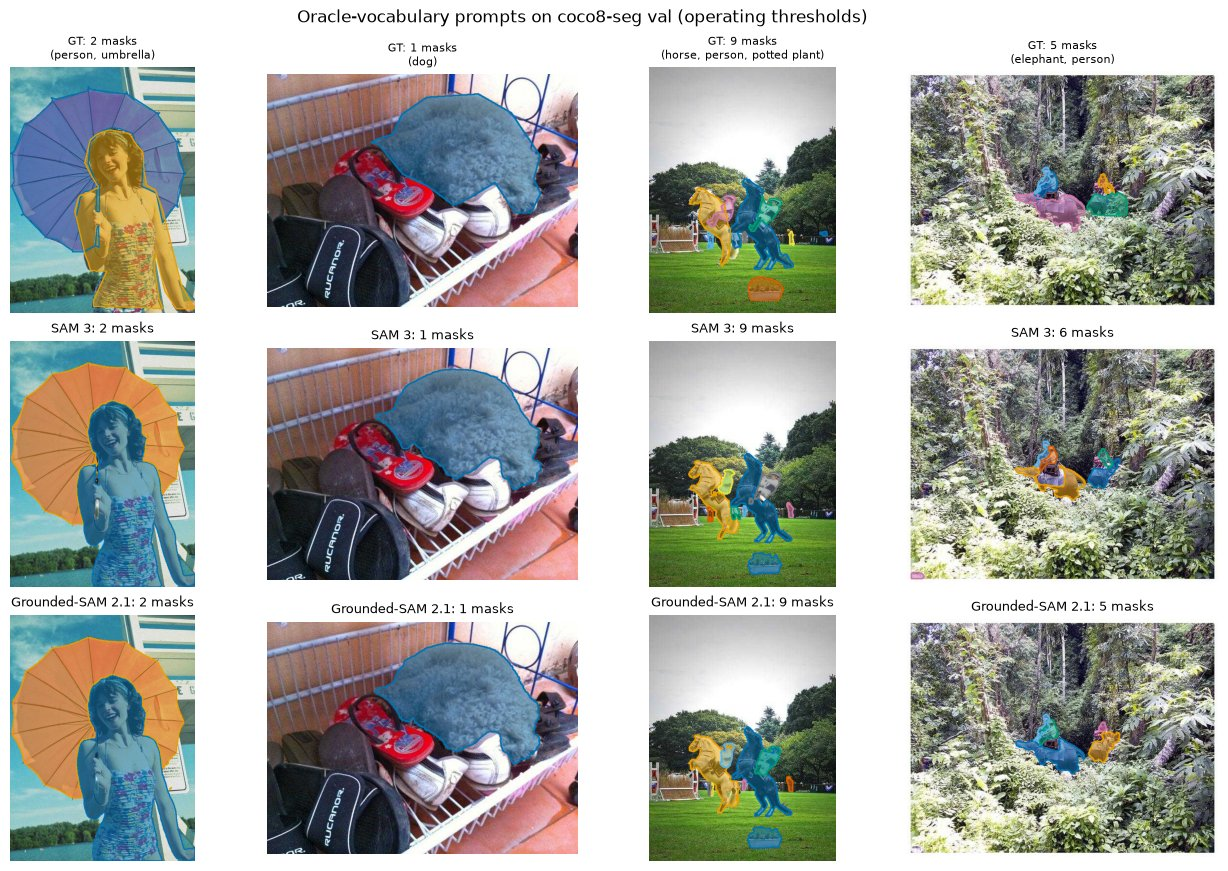

In [8]:
# --- coco8-seg val images: GT vs SAM 3 vs Grounded-SAM 2.1 with the GT class names as prompts ---
NAMES = sk.coco_names()
val = sk.load_coco_seg("coco8-seg", splits=("val",))
fig, axes = plt.subplots(3, len(val), figsize=(3.2 * len(val), 8.6))
for col, s in enumerate(val):
    prompts = sorted({NAMES[c] for c in s.classes})
    concept.set_image(s.image)
    grounded.set_image(s.image)
    m3 = [m for q in prompts for m in concept.segment(q, threshold=0.5)["masks"]]
    mg = [m for q in prompts for m in grounded.segment(q)["masks"]]
    for row, (title, masks) in enumerate([("GT", list(s.masks)), ("SAM 3", m3), ("Grounded-SAM 2.1", mg)]):
        axes[row, col].imshow(viz.overlay_masks(s.image, np.stack(masks)) if masks else s.image)
        axes[row, col].set_title(f"{title}: {len(masks)} masks", fontsize=9)
        axes[row, col].axis("off")
    axes[0, col].set_title(f"GT: {len(s.masks)} masks\n({', '.join(prompts)})", fontsize=8)
fig.suptitle("Oracle-vocabulary prompts on coco8-seg val (operating thresholds)")
viz.savefig(fig, PROJECT, "coco8_text_prompts")
sk.show_jpeg(fig)

### Latency per phrase

With the image features cached, how long does one extra phrase cost? For SAM 3 the
vision backbone is shared by all phrases; Grounding DINO re-runs its full image backbone
for every phrase in the `transformers` API, and SAM 2.1 then decodes one mask per box.

In [9]:
# --- Latency: SAM 3 image encoding, SAM 3 per phrase, Grounded-SAM per phrase ---
concept.set_image(desk)
grounded.set_image(desk)
lat = {
    "SAM 3 vision backbone (once per image)": benchmark(concept.set_image, desk, warmup=2, iters=10),
    "SAM 3 per phrase (cached image)": benchmark(concept.segment, "book", warmup=3, iters=20),
    "SAM 2.1-S image encoder (once per image)": benchmark(grounded.sam.set_image, desk, warmup=2, iters=10),
    "Grounded-SAM per phrase (GDINO + SAM 2.1-S boxes)": benchmark(grounded.segment, "book", warmup=3, iters=20),
}
latency = pd.DataFrame({k: {"mean ms": round(v["mean_ms"], 1), "p90 ms": round(v["p90_ms"], 1)}
                        for k, v in lat.items()}).T
latency

,mean ms,p90 ms
SAM 3 vision backbone (once per image),341.8,375.1
SAM 3 per phrase (cached image),42.9,45.1
SAM 2.1-S image encoder (once per image),42.5,43.1
Grounded-SAM per phrase (GDINO + SAM 2.1-S boxes),323.8,345.6


## Results

The benchmark (`benchmark_coco.py --task text`) applied the oracle-vocabulary protocol to
all 128 images of coco128-seg (929 GT instances, 71 classes) and the absent-concept test
to 3 random absent COCO class names per image (384 queries). Caveat: these are COCO
train2017 images, which YOLO26 (and very likely the other models) saw during training, so
absolute numbers are optimistic; the comparison under identical prompts is what matters.

In [10]:
# --- Load the coco128-seg text-prompt benchmark ---
from cvlab.io import load_json

text_bench = load_json(RESULTS / "text_coco128-seg.json")
meth = text_bench["methods"]
print(text_bench["meta"]["protocol"])
print(f"{text_bench['meta']['n_images']} images, {meth['SAM 3 (text)']['n_gt']} GT instances, "
      f"{meth['SAM 3 (text)']['n_classes']} classes")

prompts = GT class names of each image (oracle vocabulary); YOLO predictions filtered to the same names
128 images, 929 GT instances, 71 classes


Mask AP per method, and the hallucination test (fraction of absent-concept queries that
returned at least one instance, at the operating thresholds):

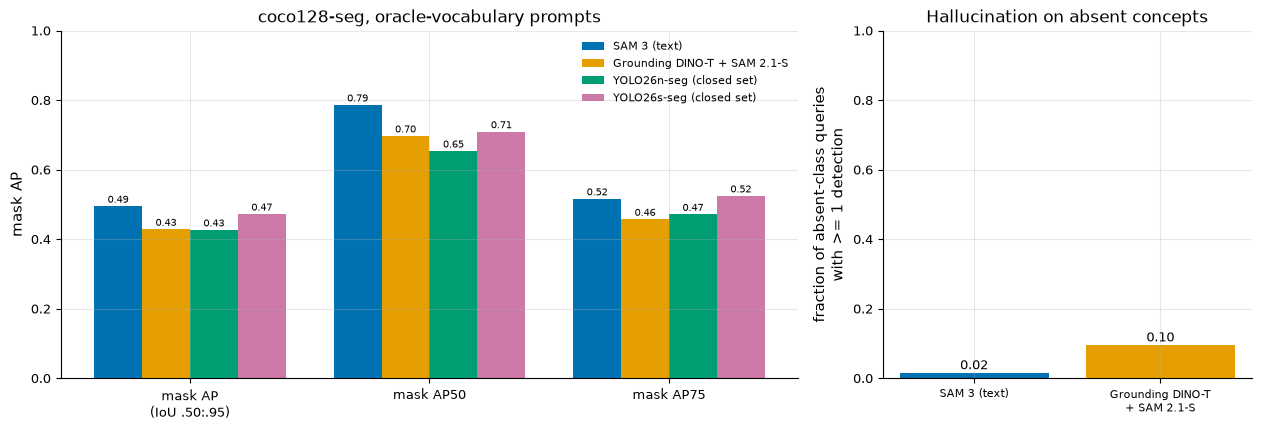

In [11]:
# --- Figure: mask AP (coco128-seg) and absent-concept hit rate ---
order = list(meth)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.2), gridspec_kw={"width_ratios": [2, 1]})
metrics = ["AP", "AP50", "AP75"]
width = 0.8 / len(order)
for i, m in enumerate(order):
    xs = np.arange(len(metrics)) + (i - (len(order) - 1) / 2) * width
    vals = [meth[m][k] for k in metrics]
    ax1.bar(xs, vals, width, label=m, color=viz.color(i, unit=True))
    for x, v in zip(xs, vals):
        ax1.text(x, v + 0.01, f"{v:.2f}", ha="center", fontsize=7)
ax1.set_xticks(range(len(metrics)), ["mask AP\n(IoU .50:.95)", "mask AP50", "mask AP75"])
ax1.set_ylim(0, 1)
ax1.set_ylabel("mask AP")
ax1.set_title("coco128-seg, oracle-vocabulary prompts")
ax1.legend(fontsize=8, loc="upper right")
prompt_methods = [m for m in order if "absent_query_hit_rate" in meth[m]]
rates = [meth[m]["absent_query_hit_rate"] for m in prompt_methods]
ax2.bar(range(len(prompt_methods)), rates, color=[viz.color(order.index(m), unit=True) for m in prompt_methods])
for x, v in enumerate(rates):
    ax2.text(x, v + 0.01, f"{v:.2f}", ha="center", fontsize=9)
ax2.set_xticks(range(len(prompt_methods)), [m.replace(" + ", "\n+ ") for m in prompt_methods], fontsize=8)
ax2.set_ylim(0, 1)
ax2.set_ylabel("fraction of absent-class queries\nwith >= 1 detection")
ax2.set_title("Hallucination on absent concepts")
viz.savefig(fig, PROJECT, "text_benchmark")
plt.show()

Summary table (benchmark numbers). *ms / prompt* is the median time to answer one phrase
over images 2-128 (image 1 includes CUDA warm-up): for SAM 3 with the image features
already cached (its vision backbone costs *image encoder ms* once per image on top); for
Grounded-SAM the full Grounding DINO pass plus SAM 2.1-S box decoding (the SAM 2.1-S image
encoder runs once per image and is not included); for YOLO26-seg one forward pass per
image, which covers all 80 classes at once. Peak VRAM was measured during the benchmark
with each method loaded alone.

In [12]:
# --- Summary table of the text-prompt benchmark + this notebook's latency measurements ---
keep = ["AP", "AP50", "AP75", "ms_per_prompt", "image_encoder_ms", "peak_vram_MiB", "params_M",
        "absent_fp_per_query", "absent_query_hit_rate"]
table = pd.DataFrame({m: {k: meth[m].get(k, np.nan) for k in keep} for m in order}).T
table.columns = ["mask AP", "mask AP50", "mask AP75", "ms / prompt", "image encoder ms", "peak VRAM (MiB)",
                 "params (M)", "absent: instances / query", "absent: hit rate"]
table.to_csv(RESULTS / "nb02_summary.csv")
table

,mask AP,mask AP50,mask AP75,ms / prompt,image encoder ms,peak VRAM (MiB),params (M),absent: instances / query,absent: hit rate
SAM 3 (text),0.4949,0.7864,0.5163,52.3,366.7,2424.0,840.4,0.016,0.016
Grounding DINO-T + SAM 2.1-S,0.4285,0.6972,0.4573,366.0,NaN,2365.0,210.8,0.104,0.096
YOLO26n-seg (closed set),0.4268,0.6538,0.4715,8.2,NaN,389.0,3.1,NaN,NaN
YOLO26s-seg (closed set),0.4724,0.7093,0.5247,8.5,NaN,418.0,11.5,NaN,NaN


### Takeaways

* **SAM 3 is the most accurate text-to-mask pipeline in this comparison.** Under identical
  oracle-vocabulary prompts on coco128-seg it reaches mask AP 0.4949 versus 0.4285 for
  Grounding DINO-T + SAM 2.1-S. The gap is largest at AP50 (0.7864 vs 0.6972), so it comes
  mostly from *finding* the right instances, not from sharper masks.
* **Given the class names, it also beats the closed-set YOLO26s-seg (0.4724).** YOLO26
  answers all 80 classes in a single 8.2-8.5 ms pass, while SAM 3 pays 366.7 ms per image
  plus 52.3 ms per phrase in the benchmark. Text prompts buy flexibility (any noun phrase,
  no retraining), not speed.
* **The presence head reduces hallucinations, which matters for a robot.** On 384
  absent-concept queries SAM 3 returned at least one instance for 1.6% of the queries,
  Grounded-SAM for 9.6% (0.016 vs 0.104 false instances per query). On the clean desk
  frame neither pipeline returned anything for the five absent concepts; the difference
  shows up on cluttered COCO scenes.
* **Desk scene:** SAM 3 returned instances for all six phrases. At its 0.35 box threshold
  Grounding DINO found no "computer monitor" and no "cable", and its second "laptop" is the
  external keyboard: the single-phrase failure mode of a detector without a presence
  head. Always inspect the masks on your own scene before trusting a phrase.
* **Cost per extra phrase:** with the image features cached, one more phrase costs SAM 3
  42.9 ms on the desk frame, versus 323.8 ms for Grounded-SAM, whose Grounding DINO pass
  re-runs its image backbone for every phrase in the `transformers` API. SAM 3 pays its
  vision backbone (341.8 ms) once per image. Both pipelines fit comfortably in 8 GB
  (benchmark peaks 2424 and 2365 MiB).
* Caveat: coco128-seg images come from COCO train2017, which these models very likely saw
  during training, so the absolute AP values are optimistic; the ranking under identical
  prompts is the informative part.

## Exercises

Solutions: `projects/05_segmentation/solutions/` (run them from the repository root).

**Exercise 1 - compositional phrases.** Concept prompts are noun phrases, so attributes
should narrow the result. On the desk frame, compare "book" with "blue book", "white
book" and "open laptop" vs "closed laptop" for both pipelines. Which one respects the
attribute?

In [13]:
# --- Exercise 1: attribute phrases ---
# TODO: for each phrase in ["book", "blue book", "white book", "laptop", "open laptop"],
#       count instances with concept.segment(phrase) and grounded.segment(phrase) and plot them.

**Exercise 2 - operating point.** Mask AP integrates over all thresholds, but a robot
needs one threshold. On coco8-seg (all 8 images, oracle vocabulary), compute SAM 3's
precision and recall at IoU 0.5 for score thresholds 0.3, 0.4, 0.5, 0.6, 0.7 and plot
the trade-off.

In [14]:
# --- Exercise 2: SAM 3 precision / recall vs score threshold ---
# TODO: for each threshold, collect predictions per image/class, match them to GT with
#       sk.mask_iou_matrix (IoU >= 0.5, greedy by score) and compute precision and recall.

**Exercise 3 - swap the mask head.** Grounded-SAM is modular: replace SAM 2.1-S by the
SAM 3 tracker (`sk.PromptableSegmenter(sk.SAM3_ID)`) as the box-to-mask stage and compute
mask AP on coco8-seg with `sk.mask_ap`. Does a better mask head fix a weaker detector?

In [15]:
# --- Exercise 3: Grounding DINO + SAM 3 tracker as the mask head ---
# TODO: grounded.sam = sk.PromptableSegmenter(sk.SAM3_ID); then build sk.Detections per
#       image (masks, scores, class ids) for the oracle prompts and call sk.mask_ap(preds, samples).